In [15]:
import sys
print(sys.executable)
print(sys.version)

from xgboost import XGBClassifier
print("XGBoost works!")
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost imbalanced-learn


/Users/laurenjang/miniforge3/envs/dsci552/bin/python
3.11.18 (main, Oct 26 2026, 11:32:31) [Clang 21.1.8 ]
XGBoost works!
Note: you may need to restart the kernel to use updated packages.


In [16]:
import sys
import numpy
import pandas
import matplotlib
import seaborn
import sklearn
import xgboost
import imblearn

print(sys.executable)
print("All libraries are working!")

/Users/laurenjang/miniforge3/envs/dsci552/bin/python
All libraries are working!


Training shape: (60000, 171)
Test shape: (16000, 171)
Training missing values: 850015
Test missing values: 228680
br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
ab_000    46329
cr_000    46329
bn_000    44009
bm_000    39549
bl_000    27277
bk_000    23034
dtype: int64
Training missing values: 0
Test missing values: 0
aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64
Number of features: 170


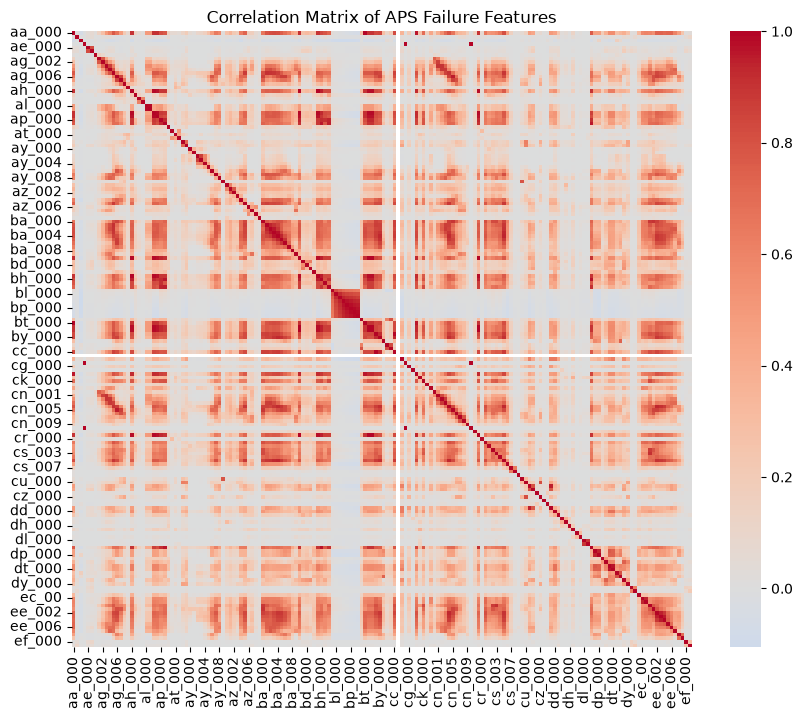

In [17]:
# 1a set up
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# loading the training and test datasets
train_df = pd.read_csv("aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv("aps_failure_test_set.csv", skiprows=20, na_values="na")

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()


#1b missing value 
# 1bi types of techniques --> after researching, I decided to go ahead with median imputation.
print("Training missing values:", train_df.isna().sum().sum())
print("Test missing values:", test_df.isna().sum().sum())

# sorting missing values by feature
missing_values = train_df.isna().sum()
print(missing_values.sort_values(ascending=False).head(10))

from sklearn.impute import SimpleImputer

X_train = train_df.drop(columns=["class"]) # training
y_train = train_df["class"]
X_test = test_df.drop(columns=["class"]) # testing
y_test = test_df["class"]

imputer = SimpleImputer(strategy="median")

#fitting imputer
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

# checking missing values
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())


#1bii
# coeff variation for 170 features
cv = X_train.std() / X_train.mean()

print(cv)
print("Number of features:", len(cv))


#1biii CM
corr_matrix = X_train.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)

plt.title("Correlation Matrix of APS Failure Features")
plt.show()



#1bi 
Common methods for handling missing values included mean, mode, median, KNN, and iterative imputations. I went ahead with median imputation as the dataset has numiercal features that might have skewed distributions and extreme outlier points. The median would be less sensitive to outliers. The SimpleImputer with strategy="median" would replace missing values and the imputer was fit on the training dataset then applied to both training and testing. 

#1bii The CV measures variability relative to the mean. In knowing this, the features with the highest CV resulted being cf_00 with 244.89, co_000 with 244.51, and ad_000 at 244.32. 

#1b iii
For the 170 features, a Pearson correlation was completed then visualized with a heatmap. THe matrix shows several clusters of positive correlations, indicating some features have overlapping information. The diagonal represents perfect self-correlation while the lighter areas illustrate weaker relationships between features. 

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
dtype: float64


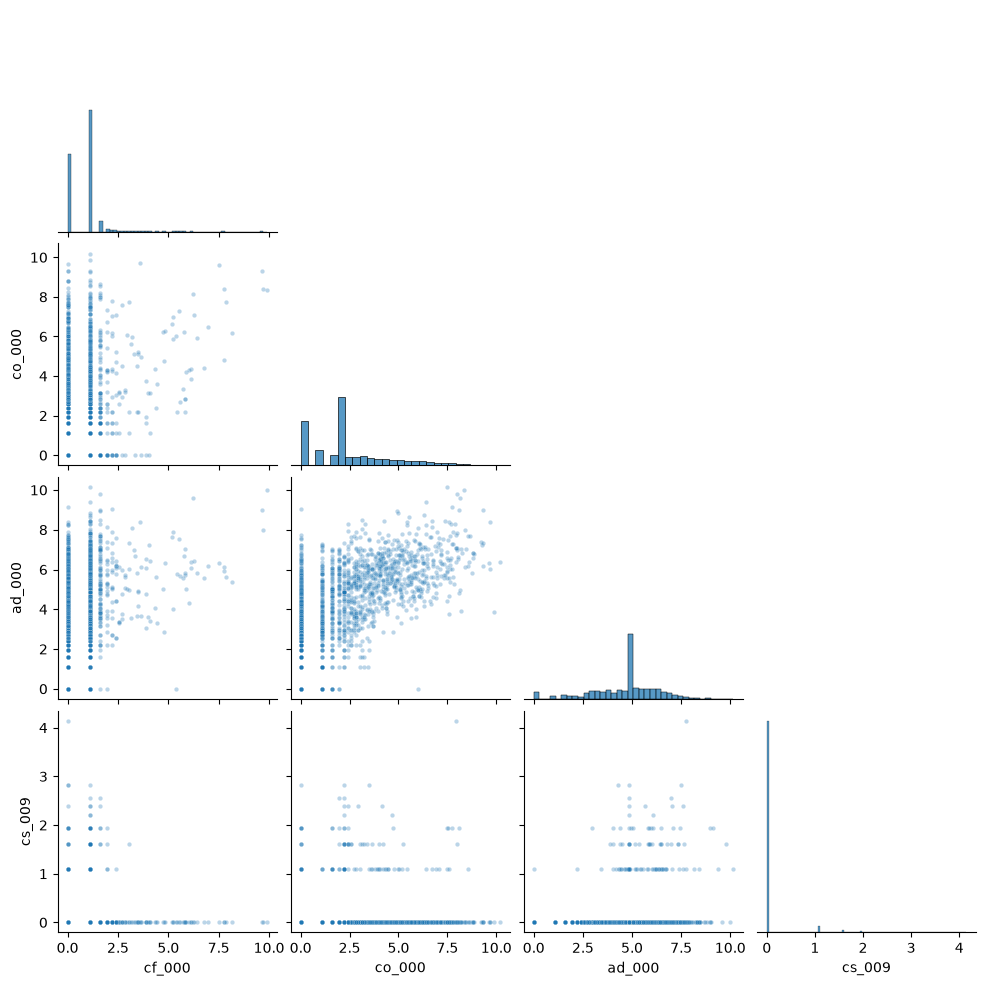

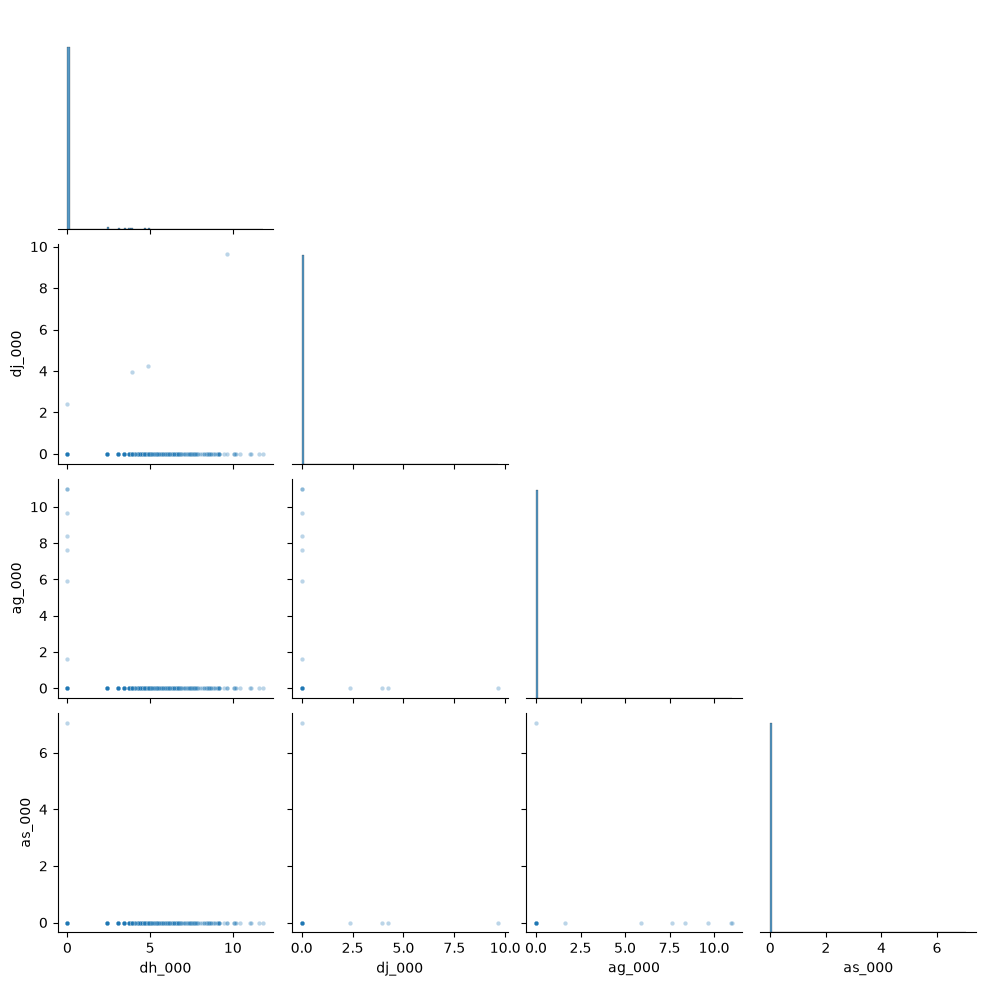

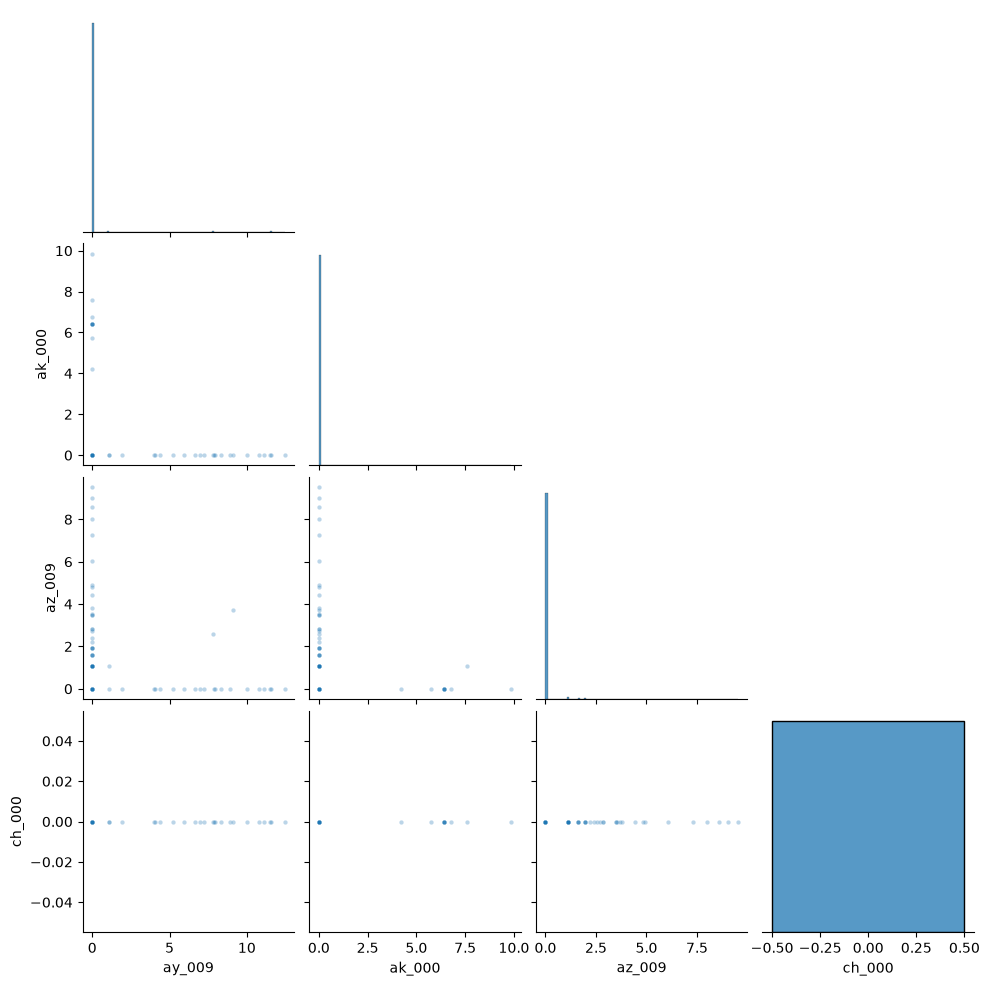

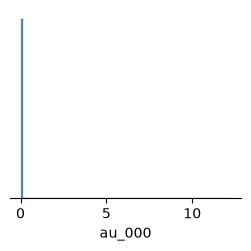

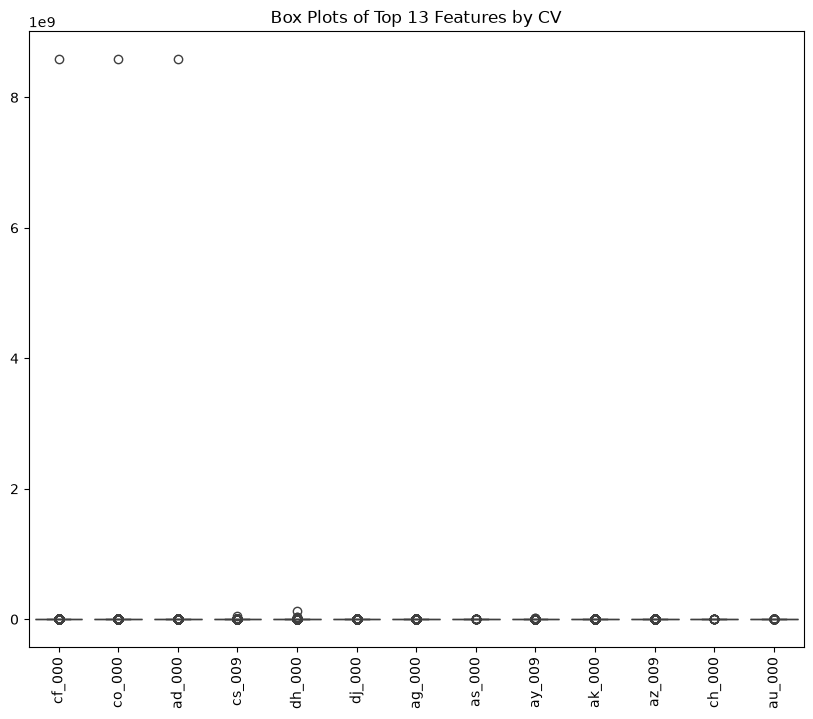

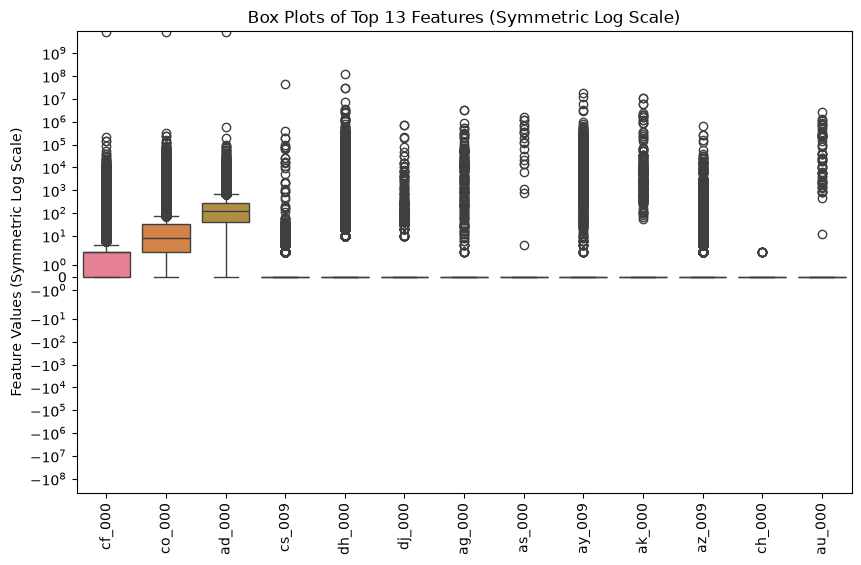

In [ ]:
#1b iv 
cv_features = X_train.std() / X_train.mean()
top_features = cv_features.replace([np.inf, -np.inf], np.nan).dropna().nlargest(13)
print(top_features)

#naming features
top_13 = top_features.index.tolist()

# log-transform for better visualization
X_log = np.log1p(X_train[top_13].clip(lower=0))

# Sample observations to reduce plotting time
X_sample = X_log.sample(n=2000, random_state=42)

# Scatterplot matrices for all 13 selected features
for i in range(0, len(top_13), 4):
    selected = top_13[i:i+4]

    if len(selected) == 1:
        selected = [top_13[0], selected[0]]

    sns.pairplot(
        X_sample[selected],
        corner=True,
        plot_kws={"alpha": 0.3, "s": 10}
    )

    plt.show()


# Box plots of the 13 selected features
plt.figure(figsize=(10, 8))
sns.boxplot(data=X_train[top_13])
plt.xticks(rotation=90)
plt.title("Box Plots of Top 13 Features by CV")
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[top_13])
plt.yscale("symlog")
plt.xticks(rotation=90)
plt.title("Box Plots of Top 13 Features (Symmetric Log Scale)")
plt.ylabel("Feature Values (Symmetric Log Scale)")
plt.show()


#1b iv scatter and box plots
I took the top 13 features with the highest coefficients of variation, based on the square root of the total number of features. The scatter plots show that majority of the observations are near zero, with few extreme values. The outliers make it hard to visualized properly hence the utilization of log. There is little that can be concluded of statistical significance at this stage, though the high CV indicates substantial relative variability, it is not enough to identify being useful for predicting APS failures. 

class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    98.333333
pos     1.666667
Name: proportion, dtype: float64


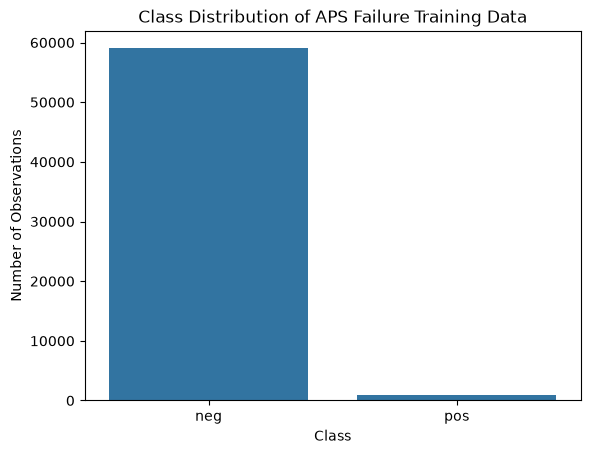

In [19]:
#class imbalance

class_counts = y_train.value_counts()
print(class_counts)
class_percentages = y_train.value_counts(normalize=True) * 100
print(class_percentages)


sns.countplot(x=y_train)
plt.title("Class Distribution of APS Failure Training Data")
plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.show()


#1b v 
The training data comes out to having 59000 negative observations and only 1000 positive observations. There is a significant class imbalance, which could lead to classification models to be bias toward the negative class, ultimately reducing the correct ability to identify APS failures. 

Random Forest training complete
Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Misclassification Rate: 1.666666666666483e-05

Test Confusion Matrix:
[[15610    15]
 [  106   269]]
Test Misclassification Rate: 0.0075625000000000275


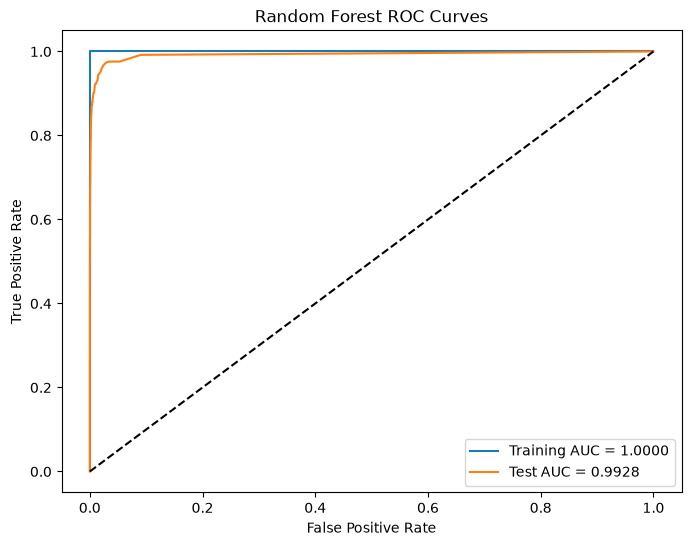

Training AUC: 1.0
Test AUC: 0.992754432
OOB Error: 0.006116666666666659
Test Error: 0.0075625000000000275
Difference: 0.0014458333333333684


In [20]:
#1c Random forest classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score


rf = RandomForestClassifier( #removing class imbalance 
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
print("Random Forest training complete")


y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

# predicting probs for positive class
pos_index = list(rf.classes_).index("pos")
y_train_prob = rf.predict_proba(X_train)[:, pos_index]
y_test_prob = rf.predict_proba(X_test)[:, pos_index]

# CMs 
train_cm = confusion_matrix(
    y_train, y_train_pred, labels=["neg", "pos"]
)
test_cm = confusion_matrix(
    y_test, y_test_pred, labels=["neg", "pos"]
)

# misclassification rates
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

print("Training Confusion Matrix:")
print(train_cm)
print("Training Misclassification Rate:", train_error)

print("\nTest Confusion Matrix:")
print(test_cm)
print("Test Misclassification Rate:", test_error)



# actual classes to binary
y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

# ROC curves
fpr_train, tpr_train, _ = roc_curve(
    y_train_binary, y_train_prob
)
fpr_test, tpr_test, _ = roc_curve(
    y_test_binary, y_test_prob
)

# AUC
train_auc = roc_auc_score(y_train_binary, y_train_prob)
test_auc = roc_auc_score(y_test_binary, y_test_prob)

# ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_train, tpr_train, label=f"Training AUC = {train_auc:.4f}")
plt.plot(fpr_test, tpr_test, label=f"Test AUC = {test_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)


# OOB error
oob_error = 1 - rf.oob_score_

print("OOB Error:", oob_error)
print("Test Error:", test_error)
print("Difference:", abs(oob_error - test_error))



#1c random forest
I trained random forest classifier with 100 trees without compensating for class imbalance. The model acheived a training AUC of 1.0 and a test AUC of 0.9928, this proved a strong overall classification conclusion. 

The misclassification rate for the training set was 0.0017% while the test misclassification rate was 0.7563%. The test confusion matrix showed 106 false negatives and 15 false positives. Althoguh the model achieved high overall accuracy, it correctly identified 269 of the 375 positive cases. From prior remarks, this seems to suggest that the class imbalance does impact the model's ability to identify APS failures, regardles of its strong performance. 

/Users/laurenjang/miniforge3/envs/dsci552/lib/python3.11/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Balanced Random Forest training complete
Balanced Training Confusion Matrix:
[[58986    14]
 [    0  1000]]
Training Misclassification Rate: 0.00023333333333330764

Balanced Test Confusion Matrix:
[[15568    57]
 [   99   276]]
Test Misclassification Rate: 0.009750000000000036


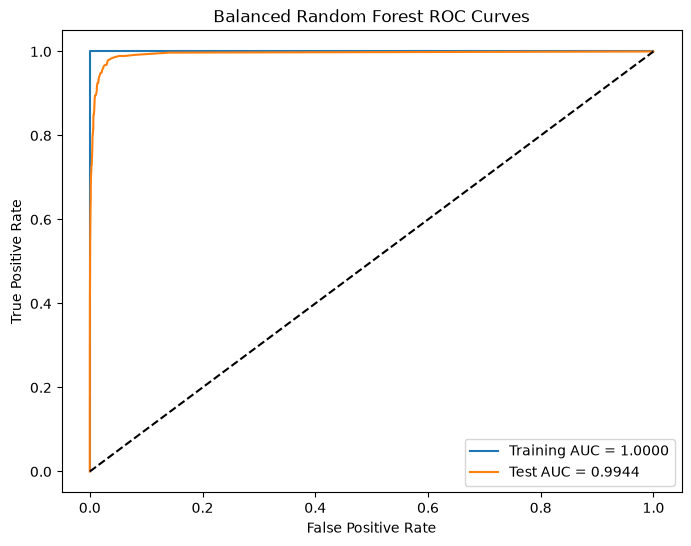

Training AUC: 1.0
Test AUC: 0.9944002559999999
Balanced OOB Error: 0.02021666666666666
Balanced Test Error: 0.009750000000000036
Difference: 0.010466666666666624
            Metric  Unbalanced RF  Balanced RF
0       Test Error       0.007563     0.009750
1         Test AUC       0.992754     0.994400
2        OOB Error       0.006117     0.020217
3  False Negatives     106.000000    99.000000
4  False Positives      15.000000    57.000000


In [21]:
#1d compensate and repeat
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)
print("Balanced Random Forest training complete")


# predicting
y_train_pred_bal = rf_balanced.predict(X_train)
y_test_pred_bal = rf_balanced.predict(X_test)

# CMs calculation
train_cm_bal = confusion_matrix(
    y_train, y_train_pred_bal, labels=["neg", "pos"]
)
test_cm_bal = confusion_matrix(
    y_test, y_test_pred_bal, labels=["neg", "pos"]
)

# misclassification rates
train_error_bal = 1 - accuracy_score(y_train, y_train_pred_bal)
test_error_bal = 1 - accuracy_score(y_test, y_test_pred_bal)

print("Balanced Training Confusion Matrix:")
print(train_cm_bal)
print("Training Misclassification Rate:", train_error_bal)
print("\nBalanced Test Confusion Matrix:")
print(test_cm_bal)
print("Test Misclassification Rate:", test_error_bal)



# predicting probs for positive class
pos_index_bal = list(rf_balanced.classes_).index("pos")

y_train_prob_bal = rf_balanced.predict_proba(X_train)[:, pos_index_bal]
y_test_prob_bal = rf_balanced.predict_proba(X_test)[:, pos_index_bal]

# ROC curves
fpr_train_bal, tpr_train_bal, _ = roc_curve(
    y_train_binary, y_train_prob_bal
)
fpr_test_bal, tpr_test_bal, _ = roc_curve(
    y_test_binary, y_test_prob_bal
)

# AUC
train_auc_bal = roc_auc_score(y_train_binary, y_train_prob_bal)
test_auc_bal = roc_auc_score(y_test_binary, y_test_prob_bal)

# ROC curves
plt.figure(figsize=(8, 6))

plt.plot(fpr_train_bal, tpr_train_bal,
         label=f"Training AUC = {train_auc_bal:.4f}")

plt.plot(fpr_test_bal, tpr_test_bal,
         label=f"Test AUC = {test_auc_bal:.4f}")

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.show()
print("Training AUC:", train_auc_bal)
print("Test AUC:", test_auc_bal)


# calculating balanced Random Forest OOB error
oob_error_bal = 1 - rf_balanced.oob_score_
print("Balanced OOB Error:", oob_error_bal)
print("Balanced Test Error:", test_error_bal)
print("Difference:", abs(oob_error_bal - test_error_bal))



comparison = pd.DataFrame({
    "Metric": ["Test Error", "Test AUC", "OOB Error",
               "False Negatives", "False Positives"],
    "Unbalanced RF": [
        test_error,
        test_auc,
        oob_error,
        test_cm[1, 0],
        test_cm[0, 1]
    ],
    "Balanced RF": [
        test_error_bal,
        test_auc_bal,
        oob_error_bal,
        test_cm_bal[1, 0],
        test_cm_bal[0, 1]
    ]
})

print(comparison)

#1d interpretation
The class balancing did improve failure detection only slightly as the false negatives decreased from 106 to 99. In addition, the overall classification error did increase from 0.7563% to 0.9750% which resulted from the false positives increasing from 15 to 57. Furthermore, the AUC only improved slightly from 0.9928 to 0.9944. 

In [ ]:
#1e XGBoost and Model Trees
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

# using OG data so imputation happens within CV folds
X_train_xgb = train_df.drop(columns=["class"])
X_test_xgb = test_df.drop(columns=["class"])

#transforming target to binary
y_train_xgb = (train_df["class"] == "pos").astype(int)
y_test_xgb = (test_df["class"] == "pos").astype(int)

#initializing
xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# pipeline for median imputation and XGBoost
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", xgb)
])


# alpha values for L1 regularization
param_grid = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]
}

# five-fold stratified CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# grid search to find the best alpha 
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=1,
    verbose=1
)

# fitting the model
grid_search.fit(X_train_xgb, y_train_xgb)

# Display results
print("Best Alpha:", grid_search.best_params_)
print("CV Accuracy:", grid_search.best_score_)
print("CV Error:", 1 - grid_search.best_score_)


# getting best model 
best_xgb = grid_search.best_estimator_

y_train_pred = best_xgb.predict(X_train_xgb)
y_test_pred = best_xgb.predict(X_test_xgb)

# misclassification errors
train_error = 1 - accuracy_score(y_train_xgb, y_train_pred)
test_error = 1 - accuracy_score(y_test_xgb, y_test_pred)

# confusion matrices
train_cm = confusion_matrix(y_train_xgb, y_train_pred)
test_cm = confusion_matrix(y_test_xgb, y_test_pred)

print("Training Confusion Matrix:")
print(train_cm)
print("Training Misclassification Error:", train_error)
print("\nTest Confusion Matrix:")
print(test_cm)
print("Test Misclassification Error:", test_error)
print("\nCross-Validation Error:", 1 - grid_search.best_score_)




Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Alpha: {'xgb__reg_alpha': 0.1}
CV Accuracy: 0.9936166666666667
CV Error: 0.0063833333333332964
Training Confusion Matrix:
[[58974    26]
 [  147   853]]
Training Misclassification Error: 0.002883333333333349

Test Confusion Matrix:
[[15608    17]
 [  106   269]]
Test Misclassification Error: 0.007687499999999958

Cross-Validation Error: 0.0063833333333332964


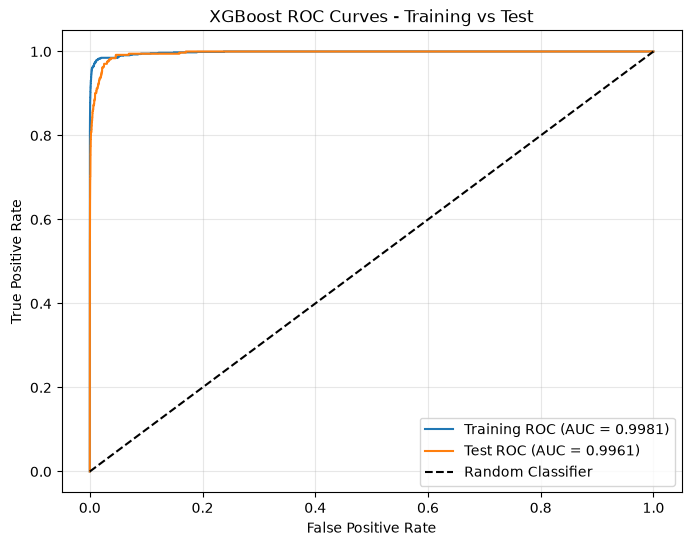

Training AUC: 0.998131186440678
Test AUC: 0.996099072


In [25]:
# predicted probs for the positive class
y_train_prob = best_xgb.predict_proba(X_train_xgb)[:, 1]
y_test_prob = best_xgb.predict_proba(X_test_xgb)[:, 1]

# ROC curves
train_fpr, train_tpr, _ = roc_curve(y_train_xgb, y_train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_xgb, y_test_prob)

# AUC scores
train_auc = roc_auc_score(y_train_xgb, y_train_prob)
test_auc = roc_auc_score(y_test_xgb, y_test_prob)

# ROC curves
plt.figure(figsize=(8, 6))

plt.plot(train_fpr, train_tpr,
         label=f"Training ROC (AUC = {train_auc:.4f})")

plt.plot(test_fpr, test_tpr,
         label=f"Test ROC (AUC = {test_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves - Training vs Test")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)


#1e interpretation
I used 5-fold stratified cross-validation in order to determine the optimal L1 regularization parameter for my XGBoost model. The best alpha was 0.1 and resulted in a cross-validation error of 0.6383%. The test error was 0.7688% which was higher than the CV error (0.6383%). The small difference implies the model performs similarly on unseen data. Both curves are close to the upper-left corner which highlights strong discrimination between the two classes. While AUC identifies and measures how well the model distinguishes between classes across classification thresholds, classification error measures the incorrect predictions at a chosen threshold. 

In [ ]:
# 1f XGBoost with SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# pipeline with imputation, SMOTE, and XGBoost
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])


# alpha values for L1 regularization
smote_param_grid = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]
}

# Five-fold CV
smote_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search with SMOTE
smote_grid_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=smote_param_grid,
    cv=smote_cv,
    scoring="accuracy",
    n_jobs=1,
    verbose=1
)

# Fit on the OG training data
smote_grid_search.fit(X_train_xgb, y_train_xgb)
print("Best Alpha:", smote_grid_search.best_params_)
print("CV Accuracy:", smote_grid_search.best_score_)
print("CV Error:", 1 - smote_grid_search.best_score_)


Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Alpha: {'xgb__reg_alpha': 0.01}
CV Accuracy: 0.9850333333333333
CV Error: 0.014966666666666684


#1f XGBoost with SMOTE

SMOTE improved failure detection as the false negatives decreased from 106 to 35, which highlights fewer actual failures. The SMOTE did increase false alarms unfortunaqtely as the false positives rose from 17 to 192, causing a higher overall test error. Lastly, in doing the model with SMOTE the sensitivity was improved to the minority class but reduced overall classification accuracy, so there's a trade off. 

Training Confusion Matrix:
[[58298   702]
 [   65   935]]
Training Misclassification Error: 0.012783333333333369

Test Confusion Matrix:
[[15433   192]
 [   35   340]]
Test Misclassification Error: 0.01418750000000002

Cross-Validation Error: 0.014966666666666684


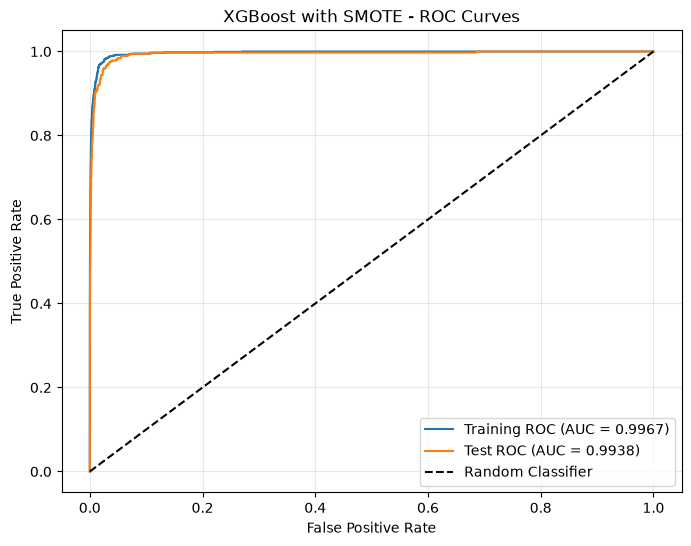

Training AUC: 0.9967366440677966
Test AUC: 0.9938276693333332


In [ ]:
#1f continuation 
best_smote_xgb = smote_grid_search.best_estimator_
y_train_pred_smote = best_smote_xgb.predict(X_train_xgb)
y_test_pred_smote = best_smote_xgb.predict(X_test_xgb)

# misclassification errors
train_error_smote = 1 - accuracy_score(y_train_xgb, y_train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test_xgb, y_test_pred_smote)

# calculating CMs
train_cm_smote = confusion_matrix(y_train_xgb, y_train_pred_smote)
test_cm_smote = confusion_matrix(y_test_xgb, y_test_pred_smote)

print("Training Confusion Matrix:")
print(train_cm_smote)
print("Training Misclassification Error:", train_error_smote)
print("\nTest Confusion Matrix:")
print(test_cm_smote)
print("Test Misclassification Error:", test_error_smote)
print("\nCross-Validation Error:", 1 - smote_grid_search.best_score_)


#ROC and AUC
# for pos class
y_train_prob_smote = best_smote_xgb.predict_proba(X_train_xgb)[:, 1]
y_test_prob_smote = best_smote_xgb.predict_proba(X_test_xgb)[:, 1]

# ROC curves
train_fpr_smote, train_tpr_smote, _ = roc_curve(
    y_train_xgb, y_train_prob_smote
)
test_fpr_smote, test_tpr_smote, _ = roc_curve(
    y_test_xgb, y_test_prob_smote
)
# AUC scores
train_auc_smote = roc_auc_score(y_train_xgb, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test_xgb, y_test_prob_smote)

# ROC curves
plt.figure(figsize=(8, 6))
plt.plot(
    train_fpr_smote, train_tpr_smote,
    label=f"Training ROC (AUC = {train_auc_smote:.4f})"
)
plt.plot(
    test_fpr_smote, test_tpr_smote,
    label=f"Test ROC (AUC = {test_auc_smote:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost with SMOTE - ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("Training AUC:", train_auc_smote)
print("Test AUC:", test_auc_smote)



#1f interpretation

The model without SMOTE resulted in higher overally accuracy and AUC, and had less false positives. The model with SMOTE identified more actual APS failures, lowering the false negatives by 67% but produced much more false positives. The AUC decreased by a small amount from 0.9961 to 0.9938, which illustrates how the overall ability was not improved with SMOTE. But what SMOTE did improve was the positive-class recall from 71.735 to 90.67% at the default threshold. 

#2 6.6.3

a - as s increases, the model would become more flexible and fit the training data better. So, the training RSS decreases or stays the same.

b - At first, increasing s reduces the underfitting and improves test performance. But afterwards, as flexibility increases more, the model may begin to overfit, which would cause test RSS to increase. 

c - As s increases, the model would become more flexible and more sensitive to changes in the training data which would increase variance.

d - As s increases, the coefficients are less restricted, which would allow the model to better capture relationships in the data. Overall, the squared bias would decrease. 

e - Irreducible error comes from inherent randomness within the data, by changing the flexibility, it would not be affected.

#3 6.6.5
a) ridge optimization

$$
\min_{\beta_1,\beta_2}
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(\beta_1^2+\beta_2^2)
$$

b) equal ridge coefficients

Since the predictors are identical, the residual sum of squares depends only on $\beta_1+\beta_2$.

$$
\beta_1^2+\beta_2^2 =
\frac{(\beta_1+\beta_2)^2+(\beta_1-\beta_2)^2}{2}
$$

For a fixed sum, the penalty is minimized when $\beta_1=\beta_2$.

c)lasso optimization**

$$
\min_{\beta_1,\beta_2}
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(|\beta_1|+|\beta_2|)
$$

d) Nonunique lasso coefficients**

Let $c=\beta_1+\beta_2$.

By the triangle inequality:

$$
|\beta_1|+|\beta_2|\geq|c|
$$

For an optimal $c>0$, any pair $(t,c-t)$ with $0\leq t\leq c$ gives the same fitted values and L1 penalty. In conclusion, the lasso solution can be nonunique when the optimal coefficient sum is nonzero.


**#4 8.4.5***

Six trees predict Red and four predict Green. Therefore, the final prediction is red. 

For Average probability: 

$$
\bar P=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=0.45
$$

As the average probability is below 0.5, the final prediction is green.

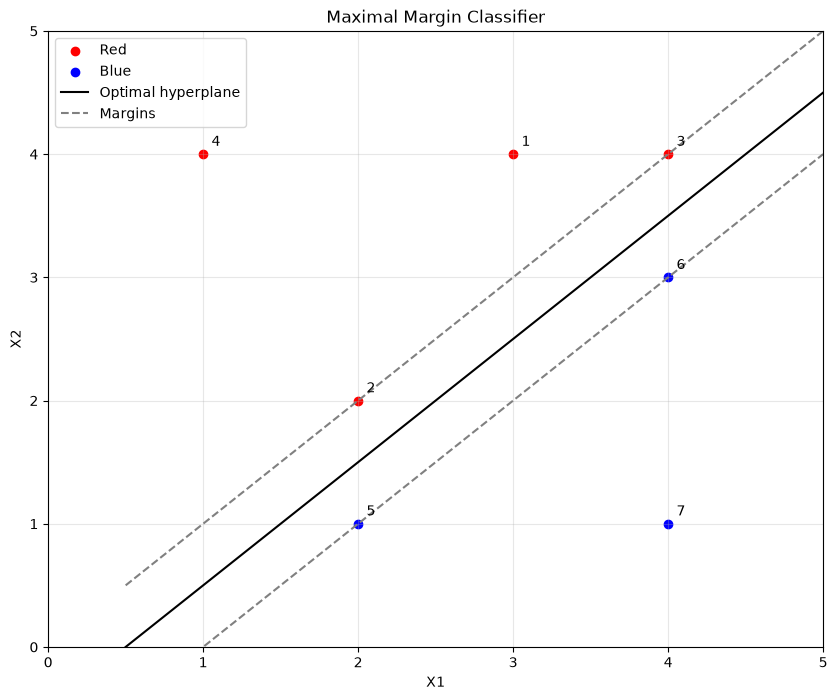

In [31]:
#5 9.7.3
import numpy as np
import matplotlib.pyplot as plt

red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])

plt.figure(figsize=(10, 8))
plt.scatter(red[:, 0], red[:, 1], color="red", label="Red")
plt.scatter(blue[:, 0], blue[:, 1], color="blue", label="Blue")
x = np.linspace(0.5, 5, 100)

# optimal sep hyperplane
plt.plot(x, x - 0.5, color="black", label="Optimal hyperplane")
plt.plot(x, x, "--", color="gray", label="Margins")
plt.plot(x, x - 1, "--", color="gray") # labeling
points = np.vstack([red, blue])
for i, (x1, x2) in enumerate(points, start=1):
    plt.annotate(str(i), (x1, x2), xytext=(6, 6),
                 textcoords="offset points")

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Maximal Margin Classifier")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

continuation #5

a) observations
The 7 observations are plotted in two classes of red and blue.

b - The optimal separating hyperplane is 
$$
X_2 = X_1 - 0.5
$$
This line divides the two classes while maximizing the margin in between them. 

c - 
The classification rule is Red if:
$$
0.5-X_1+X_2 > 0
$$
and for all else, is Blue. 

In conclusion, the coefficients are:
$$
\beta_0=0.5,\quad \beta_1=-1,\quad \beta_2=1
$$


d - 
The two margin boundaries are:
$$
X_2=X_1
$$

$$
X_2=X_1-1
$$

The distance from the dividing hyperplane to either margin boundary is:
$$
M=\frac{0.5}{\sqrt{2}}\approx0.3536
$$


e - 
The support vectorare observations 2,3,5 and 6. They are located respectively at (2,2), (4,4), (2,1), and lastly, (4,3). These observations can be found lying on the margin boundaries. 

f - 
Observation 7 wouldn't be a support vector since it lies farther away from the hyperplane. In moving it, there would not be an effect on the optimal hyperplane while it stays outside of the margin. 

g - 
An example of a nonoptimal separating hyperplane is:
$$
X_2=X_1-0.25
$$

This line divides the two classes, but the minimum margin is smaller than the optimal hyperplane's margin. 

h - 
By adding a blue observation at (3,3), this would make the classes no longer linearly separable. The new observation would lie between the existing red observations at (2,2) and (4,4) so there wouldn't be a straight line that could exactly separate the two classes. 

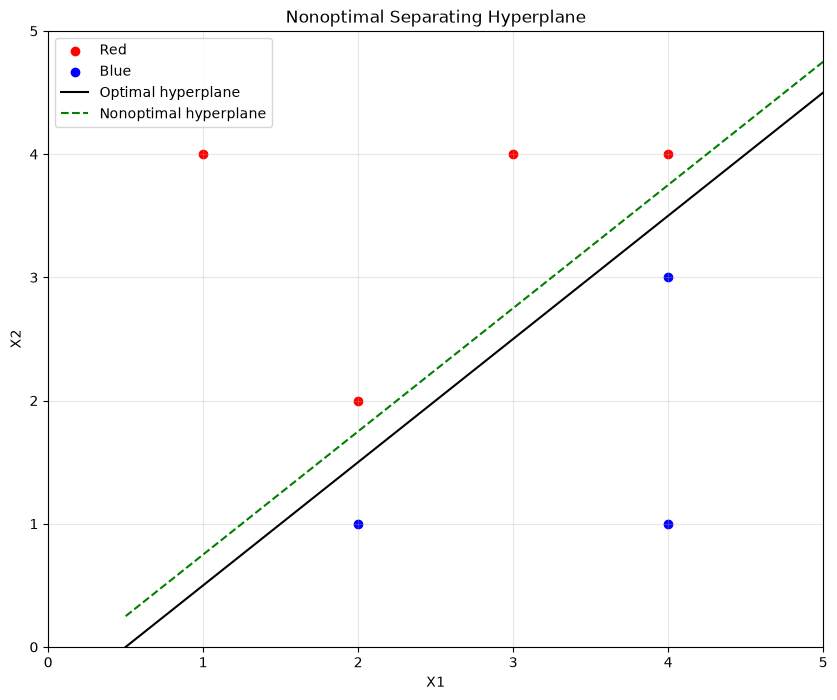

In [32]:
#5 continued part g
plt.figure(figsize=(10, 8))

plt.scatter(red[:, 0], red[:, 1], color="red", label="Red")
plt.scatter(blue[:, 0], blue[:, 1], color="blue", label="Blue")

x = np.linspace(0.5, 5, 100)
plt.plot(x, x - 0.5, color="black",
         label="Optimal hyperplane")
plt.plot(x, x - 0.25, "--", color="green",
         label="Nonoptimal hyperplane")

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Nonoptimal Separating Hyperplane")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

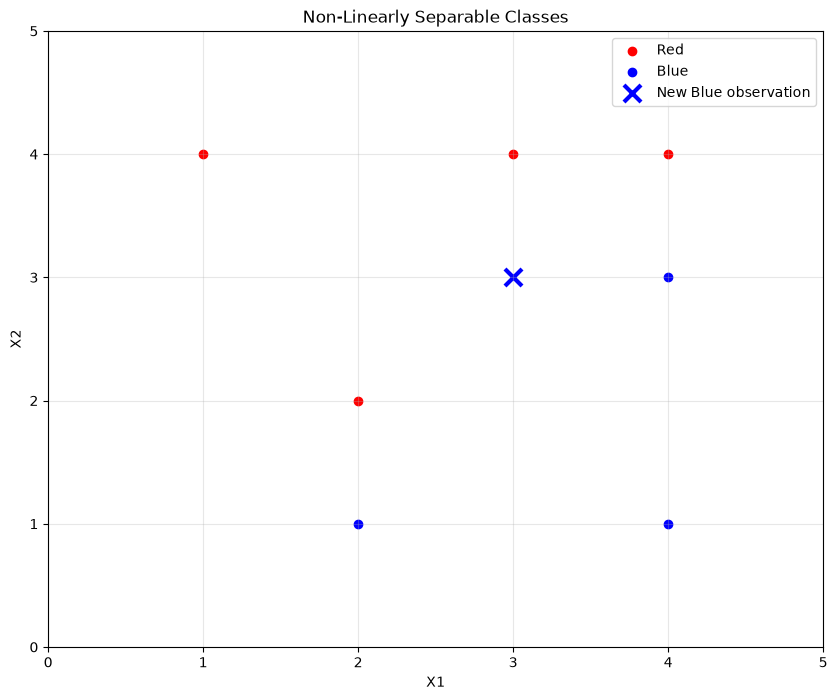

In [33]:
#5 continued part h
plt.figure(figsize=(10, 8))
plt.scatter(red[:, 0], red[:, 1], color="red", label="Red")
plt.scatter(blue[:, 0], blue[:, 1], color="blue", label="Blue")

plt.scatter(3, 3, color="blue", marker="x",
            s=150, linewidths=3, label="New Blue observation")

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Non-Linearly Separable Classes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()